# Importation et embeddings des données

In [ ]:
import pandas as pd
songs = pd.read_csv("all_songs.csv")
songs = songs.dropna(subset=["paroles"]).copy()
songs = songs[songs["paroles"].str.strip() != ""].reset_index(drop=True)

In [7]:
import numpy as np
from transformers import GPT2Tokenizer, GPT2Model
tokenizer = GPT2Tokenizer.from_pretrained('lucone83/deep-metal')
model = GPT2Model.from_pretrained('lucone83/deep-metal')
import torch
def embed_texte(texte):
    inputs = tokenizer(texte, return_tensors="pt", truncation=True, max_length=512)
    with torch.no_grad():
        output = model(**inputs)
    return output.last_hidden_state.mean(dim=1).squeeze(0).numpy()

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 331.43it/s]
[transformers] GPT2Model LOAD REPORT from: lucone83/deep-metal
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
transformer.h.{0...11}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [8]:
from tqdm.auto import tqdm
vecteurs = np.vstack([embed_texte(t) for t in tqdm(songs["paroles"], desc="Embeddings")])

Embeddings: 100%|██████████| 32007/32007 [2:18:10<00:00,  3.86it/s]  


In [9]:
emb = pd.DataFrame(
     vecteurs,
     index=pd.MultiIndex.from_frame(songs[["genre", "artiste", "titre", "position"]]),
     columns=[f"dim_{i}" for i in range(vecteurs.shape[1])]
 )

In [10]:
emb.to_csv("embeddings_par_genre_all.csv")

## Classification

In [34]:
import numpy as np
import pandas as pd
emb = pd.read_csv("embeddings_par_genre_all.csv", index_col=["genre", "artiste", "titre", "position"])

In [36]:
X = emb.xs(0, level="position", drop_level=False)
X_vals = X.to_numpy()
y = X.index.get_level_values("genre").to_numpy()
groups = X.index.get_level_values("artiste").to_numpy()

In [37]:
from sklearn.model_selection import GroupShuffleSplit

gss1 = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=0)
dev_idx, test_idx = next(gss1.split(X_vals, y, groups))

X_dev, y_dev, g_dev = X_vals[dev_idx], y[dev_idx], groups[dev_idx]
X_test, y_test = X_vals[test_idx], y[test_idx]

gss2 = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=0)
train_idx, val_idx = next(gss2.split(X_dev, y_dev, g_dev))

X_train, y_train, g_train = X_dev[train_idx], y_dev[train_idx], g_dev[train_idx]
X_val, y_val = X_dev[val_idx], y_dev[val_idx]

C:  12%|█▎        | 1/8 [00:19<02:15, 19.43s/it]

C=0.001 -> 0.111 ± 0.024


C:  25%|██▌       | 2/8 [00:43<02:12, 22.07s/it]

C=0.005179 -> 0.112 ± 0.026


C:  38%|███▊      | 3/8 [01:14<02:10, 26.01s/it]

C=0.02683 -> 0.103 ± 0.026


C:  50%|█████     | 4/8 [02:01<02:18, 34.67s/it]

C=0.1389 -> 0.100 ± 0.029


C:  62%|██████▎   | 5/8 [02:48<01:56, 38.97s/it]

C=0.7197 -> 0.100 ± 0.031


C:  75%|███████▌  | 6/8 [03:38<01:25, 42.77s/it]

C=3.728 -> 0.100 ± 0.030


C:  88%|████████▊ | 7/8 [04:48<00:51, 51.54s/it]

C=19.31 -> 0.099 ± 0.029


C: 100%|██████████| 8/8 [05:39<00:00, 42.40s/it]


C=100 -> 0.099 ± 0.031


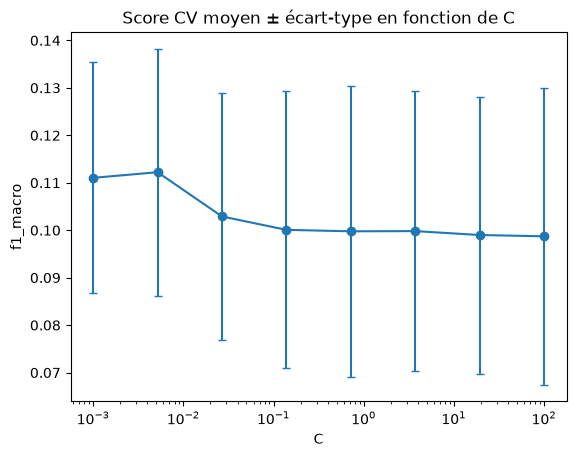

C = 0.005179 (moyenne 0.112 ± 0.026)


In [58]:
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from tqdm.auto import tqdm


C_values = np.logspace(-3, 2, 8)
cv = StratifiedGroupKFold(n_splits=5, shuffle=True)

mean = []
std = []
for c in tqdm(C_values, desc="C"):
    pipe = Pipeline([("scale", StandardScaler()), ("classifier", LogisticRegression(C=c, max_iter=2000, class_weight="balanced")),])
    scores = cross_val_score(pipe, X_train, y_train, groups=g_train, cv=cv,scoring="f1_macro")
    mean.append(scores.mean())
    std.append(scores.std())
    tqdm.write(f"C={c:.4g} -> {scores.mean():.3f} ± {scores.std():.3f}")

plt.figure()
plt.title("Score CV moyen ± écart-type en fonction de C")
plt.errorbar(C_values, mean, yerr=std, marker="o", capsize=3)
plt.xscale("log")
plt.xlabel("C")
plt.ylabel("f1_macro")
plt.show()

i_best = np.argmax(mean)
C_best = C_values[i_best]
print(f"C = {C_best:.4g} (moyenne {mean[i_best]:.3f} ± {std[i_best]:.3f})")

In [59]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report

base = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

model_selectionne = Pipeline([('scale', StandardScaler()), ('classifier', LogisticRegression(C=C_best, max_iter =2000,class_weight="balanced"))])

model_selectionne.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scale', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](17,)","['Black','Death','Epic Heavy',...,'Sludge','Speed','Thrash']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,768
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [60]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score

modeles = {
    "baseline (majoritaire)": base,
    "régression logistique": model_selectionne,
}

for nom, m in modeles.items():
    y_p = m.predict(X_test)
    y_proba = m.predict_proba(X_test)[:,1]
    print(f"{nom:25s} acc={accuracy_score(y_test, y_p):.3f}  "
          f"bal_acc={balanced_accuracy_score(y_test, y_p):.3f}  "
          f"f1={f1_score(y_test, y_p, average='macro'):.3f} ")

baseline (majoritaire)    acc=0.364  bal_acc=0.100  f1=0.053 
régression logistique     acc=0.110  bal_acc=0.051  f1=0.030 


C:\Users\LOZAY\OneDrive\Documents\pao\metal-mining\.pao\Lib\site-packages\sklearn\metrics\_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


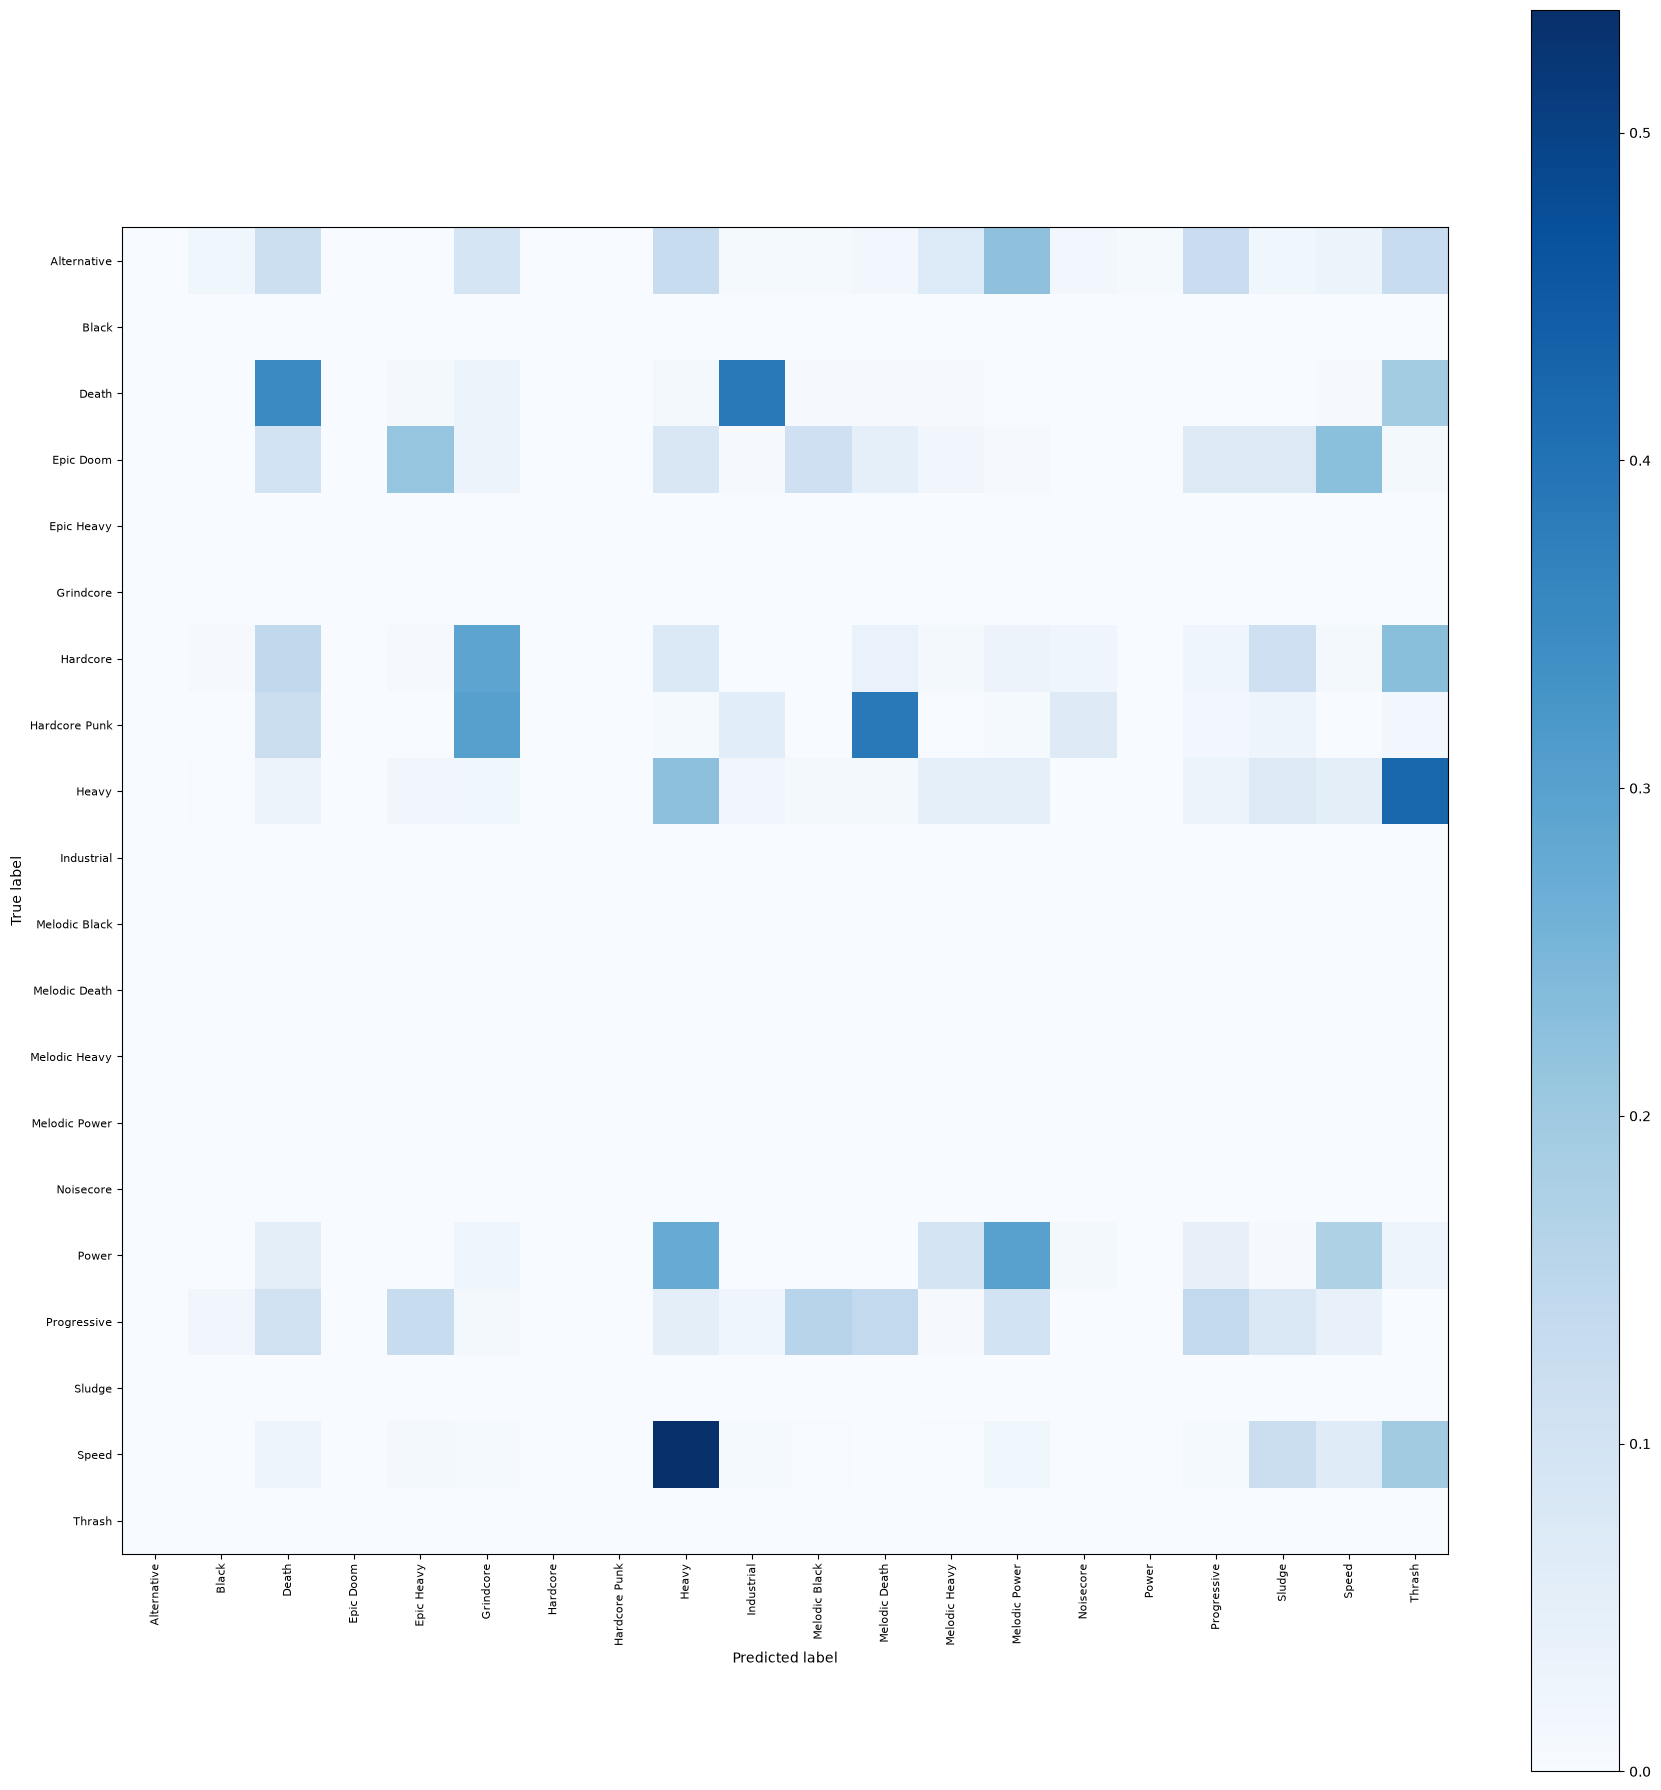

In [61]:
from sklearn.metrics import ConfusionMatrixDisplay
y_pred_valid = model_selectionne.predict(X_val)
fig, ax = plt.subplots(figsize=(18, 18))
ConfusionMatrixDisplay.from_predictions(
    y_val, y_pred_valid,
    normalize="true",
    include_values=False,
    xticks_rotation=90,
    cmap="Blues",
    ax=ax,
    colorbar=True,
)
ax.tick_params(axis="both", labelsize=8)
plt.tight_layout()
plt.show()